# Qiskit Fall Fest 2026
## Challenge 1: Predict the Output

**Name:** Janaki Jetti 

**Experiment:** Single-Qubit Quantum Circuits

### Aim
To create and simulate three single-qubit quantum circuits using Qiskit, predict their measurement outcomes, execute each circuit for 100 shots, and compare the predictions with actual results using histograms.

## Theory

A qubit is the basic unit of quantum information. When measured, a qubit gives either 0 or 1.

- **X Gate:** Flips the qubit state from 0 to 1 or from 1 to 0.
- **Hadamard (H) Gate:** Creates an equal superposition when applied to the initial state |0⟩.
- **Measurement:** Converts the quantum state into a classical result, 0 or 1.
- **Shots:** The number of times a circuit is executed. In this experiment, each circuit is executed for 100 shots.

Qiskit is a Python framework used to create and simulate quantum circuits.

In [13]:

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

simulator = AerSimulator()

print("Qiskit libraries imported successfully!")


Qiskit libraries imported successfully!



## Circuit A: One X Gate

### Prediction
The qubit starts in state |0⟩. Applying one X gate changes the state to |1⟩.

**Expected result:** All 100 measurements should be 1.


     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Circuit A Results: {'1': 100}


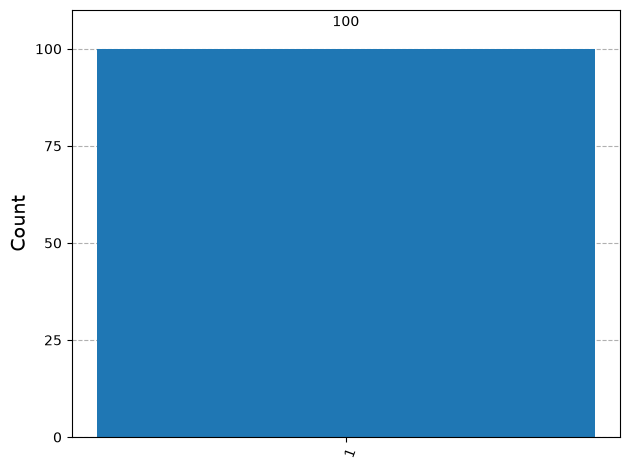

In [14]:

qc_a = QuantumCircuit(1, 1)

qc_a.x(0)
qc_a.measure(0, 0)

print(qc_a.draw(output="text"))

compiled_a = transpile(qc_a, simulator)
result_a = simulator.run(compiled_a, shots=100).result()
counts_a = result_a.get_counts()

print("Circuit A Results:", counts_a)

plot_histogram(counts_a)



### Observation

The X gate flipped the qubit from |0⟩ to |1⟩. All 100 measurements produced 1, which matches the prediction.

**Result:** The prediction was correct.



## Circuit B: Two X Gates

### Prediction
The first X gate changes |0⟩ to |1⟩. The second X gate changes |1⟩ back to |0⟩.

**Expected result:** All 100 measurements should be 0.


     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 
Circuit B Results: {'0': 100}


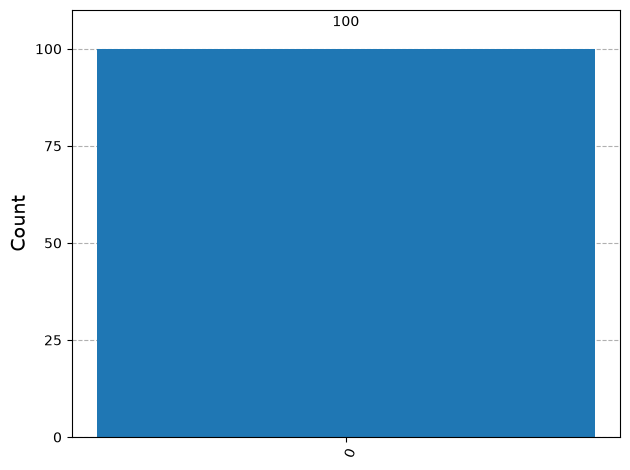

In [15]:

qc_b = QuantumCircuit(1, 1)

qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

print(qc_b.draw(output="text"))

compiled_b = transpile(qc_b, simulator)
result_b = simulator.run(compiled_b, shots=100).result()
counts_b = result_b.get_counts()

print("Circuit B Results:", counts_b)

plot_histogram(counts_b)



### Observation

Two consecutive X gates returned the qubit to its initial state |0⟩. All 100 measurements produced 0, matching the prediction.

**Result:** The prediction was correct.



## Circuit C: One Hadamard Gate

### Prediction
The H gate creates an equal superposition of |0⟩ and |1⟩.

**Expected result:** Approximately 50 measurements of 0 and 50 measurements of 1 out of 100 shots.

The exact counts may vary between executions.


     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Circuit C Results: {'0': 55, '1': 45}


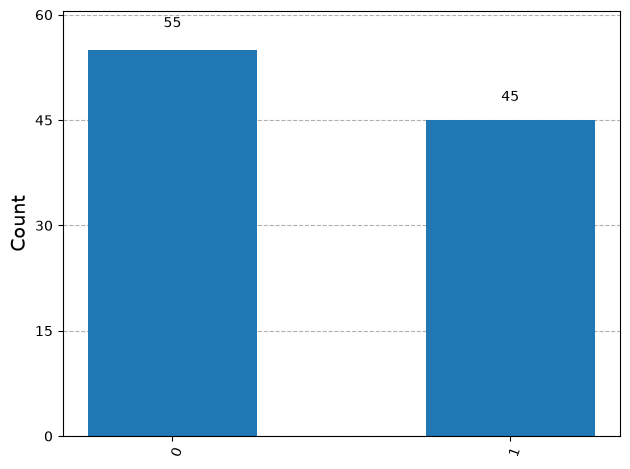

In [16]:

qc_c = QuantumCircuit(1, 1)

qc_c.h(0)
qc_c.measure(0, 0)

print(qc_c.draw(output="text"))

compiled_c = transpile(qc_c, simulator)
result_c = simulator.run(compiled_c, shots=100).result()
counts_c = result_c.get_counts()

print("Circuit C Results:", counts_c)

plot_histogram(counts_c)



### Observation

The Hadamard gate created an equal superposition. Measurement produced both 0 and 1, with counts expected to be approximately equal over many shots.

The exact counts fluctuate because quantum measurement is probabilistic.

**Result:** The prediction is supported if the counts are approximately balanced.



## Comparison of All Three Circuits

| Circuit | Gates Applied | Predicted Outcome | Actual Outcome |
|---|---|---|---|
| A | One X gate | 100 ones | As shown by counts_a |
| B | Two X gates | 100 zeros | As shown by counts_b |
| C | One H gate | Approximately 50 zeros and 50 ones | As shown by counts_c |

### Analysis

Circuit A always produces 1, while Circuit B always produces 0 in an ideal simulator. Circuit C produces probabilistic outcomes, so its counts may change between runs.


In [17]:

from IPython.display import display, Markdown

comparison = f"""
| Circuit | Prediction | Actual Counts |
|---|---|---|
| A | 100 ones | `{counts_a}` |
| B | 100 zeros | `{counts_b}` |
| C | Approximately 50 zeros and 50 ones | `{counts_c}` |
"""

display(Markdown(comparison))



| Circuit | Prediction | Actual Counts |
|---|---|---|
| A | 100 ones | `{'1': 100}` |
| B | 100 zeros | `{'0': 100}` |
| C | Approximately 50 zeros and 50 ones | `{'0': 55, '1': 45}` |



## Conclusion

In this experiment, three single-qubit quantum circuits were created and simulated using Qiskit.

The first circuit demonstrated the bit-flip operation of the X gate. The second circuit showed that applying two X gates returns the qubit to its initial state. The third circuit demonstrated superposition using the Hadamard gate.

Each circuit was executed for 100 shots, and the measurement results were visualized using histograms. The observed outcomes were compared with the initial predictions.

This experiment helped us understand quantum gates, measurement, superposition, and probabilistic outcomes in quantum computing.
